# GCV grid search versus repeated searches: six solvers, multiple orders

This notebook extends the six-method solver benchmark and **measures real selection of a smoothing parameter** (not just reconstructing several curves). Each search evaluates the *same* classical GCV criterion,

$$\operatorname{GCV}(\lambda)=\frac{n\lVert y-\widehat\tau_\lambda\rVert_2^2}{\bigl(n-\operatorname{tr}(H_\lambda)\bigr)^2},
\quad H_\lambda=(I+\lambda D_d^\top D_d)^{-1}.$$

For fixed numeric $\mu$, the right hand side is $y+\lambda\mu D_d^\top\mathbf1$. This changes fitted values but *not* $H_\lambda$ or EDF.

## Experimental factors

- **Six numerical methods:** fresh dense, cached dense, SVD, general banded, dense Cholesky and banded Cholesky.
- **Two grid policies:** equally spaced in $\log\lambda$ and equally spaced in normalized smoothness $S$ then mapped to $\lambda$; both share the same finite penalty endpoints and the same $M$.
- **Grid budgets $M$:** 5 and 11 candidates in this hosted quick-preset example. The local full preset adds 21.
- **Difference orders $d$:** 1, 2, 3, 4 in the quick preset, and 5 in the full preset.
- **Repeated series $R$:** 1 versus 4 independent series at the same $(n,d)$ in the quick preset, and 10 in the full preset.
- **Fixed difference-reference means:** $\mu=0$ and $\mu=0.15$ on *the same observations*.
- **Cold versus warm:** cold reconstructs the solver for every series; warm prepares a single grid-specific solver, reuses the SVD or Cholesky factorizations where possible, and caches EDF across series.

**Critical:** The warm Cholesky methods still factor once *per distinct penalty*, not once for the entire grid. They can reuse that factor when multiple series are processed at the *same* penalty. The six methods do not become equally efficient for trace calculations.

These are genuine total-time measurements on the machine recorded below, not invented speedups or forecasts. The normalized S grid excludes $0,1$ in this timing benchmark to avoid singular/end-limit numerical issues for dense finite factorizations. The separate S-grid tutorial covers the exact endpoints and much closer to 1. Here the **same safe penalty endpoints** are used for both policies, making their differences attributable to candidate placement rather than search width.

In [1]:
import awesomefigures as af
from matplotlib_inline.backend_inline import set_matplotlib_formats
af.set_style("elegante", font="DejaVu Sans", use_tex=False,
             palette="okabe-ito", rasterize=False)
set_matplotlib_formats("svg", "png")
from trendestimation._docs_style import apply_documentation_figure_style
apply_documentation_figure_style()


## 1. Load measured results and verify provenance

The reference CSV is generated by GitHub Actions and is intentionally kept separate from your Windows 11 VM measurements. The local benchmark writes to `paper/benchmarks/results/grid_reuse/`. Results contain setup, search, total median and median absolute deviation separately. Candidate-grid inversion is measured separately from solver-specific timings.

In [2]:
import csv
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

root=next((folder for folder in (Path.cwd(),*Path.cwd().parents)
           if (folder/"paper/benchmarks/grid_reuse_reference/gcv_grid_timings.csv").is_file()),None)
if root is None:
    raise FileNotFoundError("Benchmark reference CSVs not found. Run grid_reuse_study.py "
                            "with --output-dir paper/benchmarks/grid_reuse_reference.")
folder=root/"paper/benchmarks/grid_reuse_reference"
def read(name):
    with (folder/name).open(encoding="utf-8",newline="") as file:
        return list(csv.DictReader(file))
rows=read("gcv_grid_timings.csv")
bounds=read("grid_metadata.csv")
environment=json.loads((folder/"environment.json").read_text(encoding="utf-8"))
methods=("dense_fresh","dense_cached","spectral","banded",
         "dense_cholesky","banded_cholesky")
names=("Dense fresh","Dense cached","SVD","General banded",
       "Dense Cholesky","Banded Cholesky")
colors=("#9299a7","#d4a043","#205fd4","#138b94","#855bb4","#bd506d")
print("Host:",environment["platform"])
print("Python:",environment["python"].split()[0],
      "NumPy:",environment["numpy"],"SciPy:",environment["scipy"])
print("Reference preset:",environment["preset"],
      "BLAS threads:",environment["blas_threads"],
      "repetitions:",environment["repeats"])
print("Measured GCV solver observations:",len(rows),"candidate policies:",len(bounds))
assert {r["method"] for r in rows}==set(methods)
assert {float(r["mu"]) for r in rows}=={0.0,0.15}
assert {r["reuse"] for r in rows}=={"cold","warm"}
assert {r["grid_policy"] for r in rows}=={"log_lambda","uniform_s"}
print("Maximum solver-versus-spectral GCV score difference:",
      max(float(r["max_score_difference"]) for r in rows))


Host: Linux-6.17.0-1022-azure-x86_64-with-glibc2.39
Python: 3.11.17 NumPy: 2.4.6 SciPy: 1.17.1
Reference preset: quick BLAS threads: 1 repetitions: 3
Measured GCV solver observations: 768 candidate policies: 16
Maximum solver-versus-spectral GCV score difference: 1.7363256665792193e-10


## 2. Grid size versus runtime

For one series at $n=48,d=2,\mu=0$, compare $M=5$ versus $M=11$ and cold preparation versus shared warm factorization. End-to-end includes solver initialization and native EDF computations, but excludes mapping the candidate S targets to penalties (a *common* cost, reported below). This is a **GCV grid search**: the minimum score is selected separately for every series.

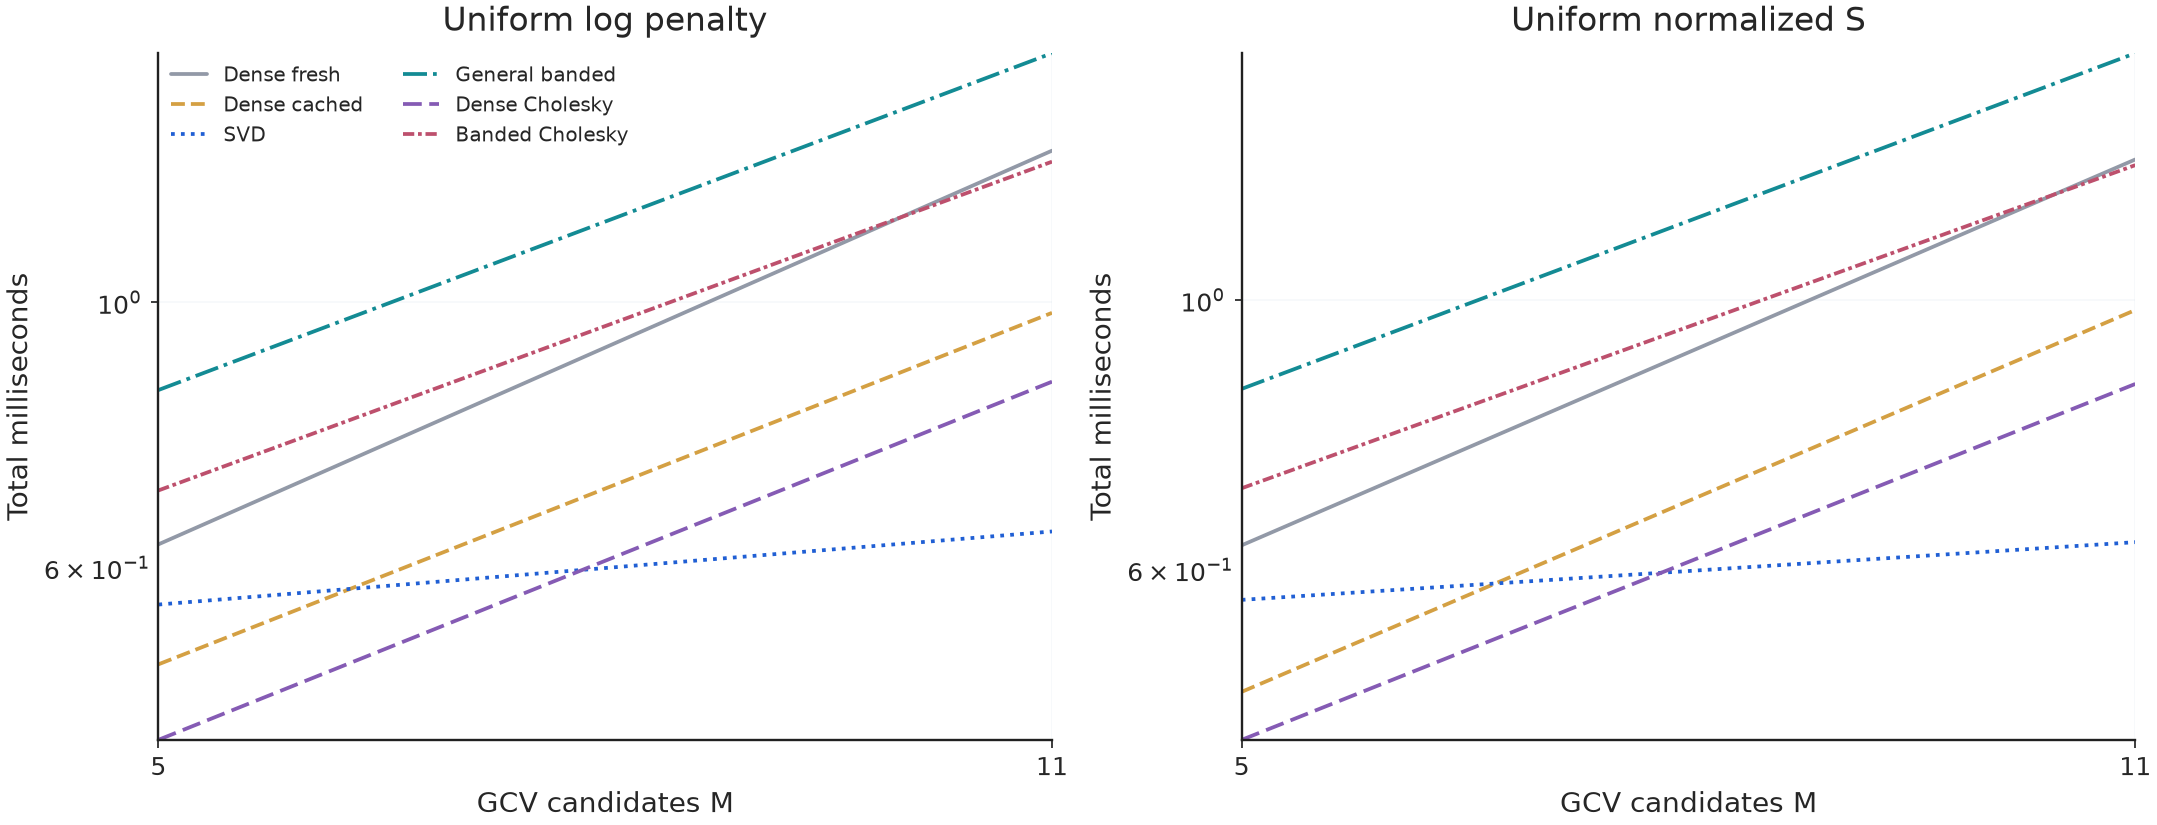

In [3]:
def subset(**conditions):
    return [r for r in rows if all(
        (float(r[k])==float(v) if k in ("mu",) else
         int(r[k])==int(v) if k in ("n","d","M","R") else r[k]==v)
        for k,v in conditions.items())]

fig,axes=plt.subplots(1,2,figsize=(12,4.6),layout="constrained")
for ax,(policy,title) in zip(axes,(("log_lambda","Uniform log penalty"),
                                   ("uniform_s","Uniform normalized S"))):
    for method,label,color in zip(methods,names,colors):
        t=[]
        for M in (5,11):
            r=subset(n=48,d=2,M=M,R=1,mu=0.0,
                     grid_policy=policy,reuse="cold",method=method)
            assert len(r)==1,(method,M)
            t.append(1000*float(r[0]["total_median_s"]))
        ax.plot((5,11),t,marker="o",lw=1.5,color=color,label=label)
    ax.set(xlabel="GCV candidates M",ylabel="Total milliseconds",
           title=title)
    ax.set_yscale("log")
    ax.set_xticks((5,11))
    ax.grid(alpha=.2)
axes[0].legend(ncol=2,fontsize=8,frameon=False)
plt.show()


## 3. How much does repeated-search preprocessing reuse help?

The same **four independent datasets** are searched on the same $M=11$ grid. Cold repeats model creation and all factorization/EDF work for each dataset. Warm amortizes work that is independent of $y$: spectral basis, Cholesky factors at each candidate, and (when possible) EDF values.

Both paths calculate exactly the same GCV score and select the same optimum **for each dataset**. A faster warm result does not mean that Cholesky became faster at searching *new penalties*; it benefits specifically from revisiting the same candidates on multiple series.

Dense fresh       : cold/warm=1.01x; cold=5.231 ms, warm=5.177 ms
Dense cached      : cold/warm=1.79x; cold=3.932 ms, warm=2.192 ms
SVD               : cold/warm=2.76x; cold=2.451 ms, warm=0.888 ms
General banded    : cold/warm=1.94x; cold=6.275 ms, warm=3.234 ms
Dense Cholesky    : cold/warm=2.28x; cold=3.436 ms, warm=1.507 ms
Banded Cholesky   : cold/warm=2.82x; cold=5.167 ms, warm=1.830 ms


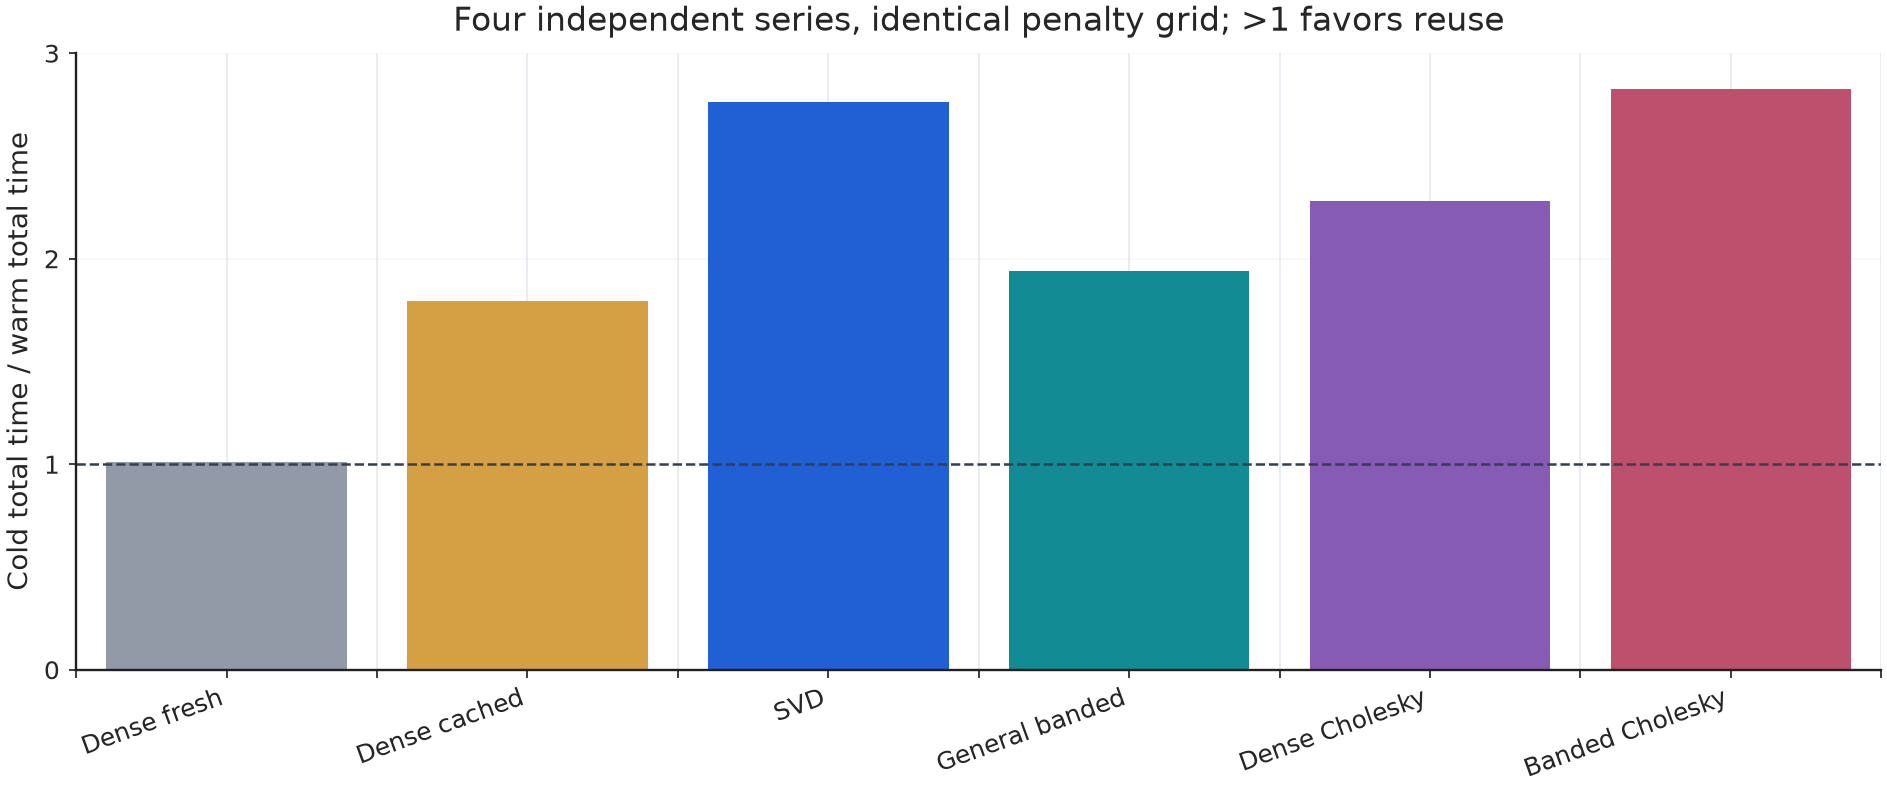

In [4]:
fig,ax=plt.subplots(figsize=(10.5,4.4),layout="constrained")
for i,(method,label,color) in enumerate(zip(methods,names,colors)):
    cold=subset(n=48,d=2,M=11,R=4,mu=0.0,
                grid_policy="log_lambda",reuse="cold",method=method)
    warm=subset(n=48,d=2,M=11,R=4,mu=0.0,
                grid_policy="log_lambda",reuse="warm",method=method)
    assert len(cold)==len(warm)==1
    ratio=float(cold[0]["total_median_s"])/float(warm[0]["total_median_s"])
    ax.bar(i,ratio,color=color)
    print(f"{label:<18}: cold/warm={ratio:.2f}x; "
          f"cold={1000*float(cold[0]['total_median_s']):.3f} ms, "
          f"warm={1000*float(warm[0]['total_median_s']):.3f} ms")
ax.axhline(1,color="#333f4f",lw=1,ls="--")
ax.set_xticks(range(6),names,rotation=20,ha="right")
ax.set(ylabel="Cold total time / warm total time",
       title="Four independent series, identical penalty grid; >1 favors reuse")
ax.grid(axis="y",alpha=.2)
plt.show()


## 4. Difference order $d$ and bandwidth

For a fixed $n=48$, each higher difference order increases the bandwidth of the PLS system. The complexity of a banded factorization is approximately $O(nd^2)$ (setup per penalty), while spectral preprocessing is broadly $O(n^3)$ and dense Cholesky per factorization is also cubic. Low-order banded methods therefore often excel, but the crossover needs measurement.

This chart compares all tested orders using the **same log-penalty grid candidate budget**, with fixed numeric $\mu$ and *one* observed series.

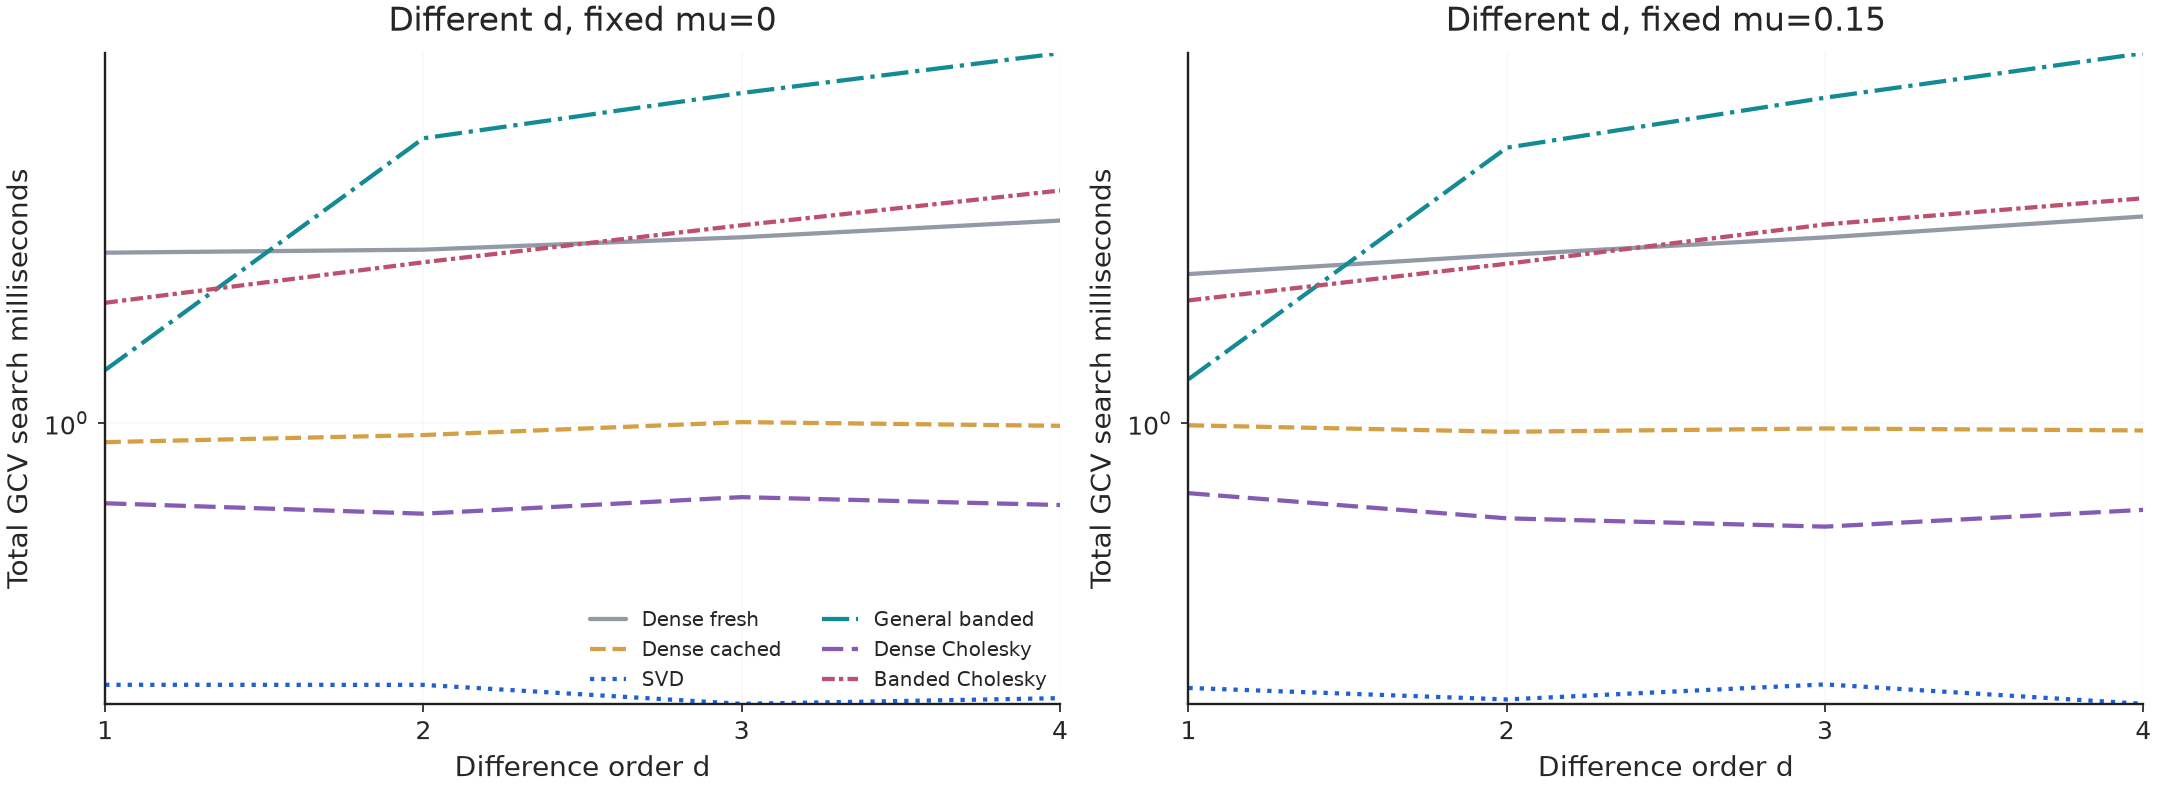

In [5]:
fig,axes=plt.subplots(1,2,figsize=(12,4.4),layout="constrained")
for ax,mu in zip(axes,(0.0,0.15)):
    orders=sorted({int(r["d"]) for r in subset(M=11,R=1,mu=mu,
                      grid_policy="log_lambda",reuse="cold")})
    for method,label,color in zip(methods,names,colors):
        times=[]
        for d in orders:
            hits=subset(n=48,d=d,M=11,R=1,mu=mu,
                        grid_policy="log_lambda",reuse="cold",method=method)
            assert len(hits)==1
            times.append(1000*float(hits[0]["total_median_s"]))
        ax.plot(orders,times,marker="o",lw=1.7,color=color,label=label)
    ax.set(xlabel="Difference order d",ylabel="Total GCV search milliseconds",
           title=f"Different d, fixed mu={mu:g}")
    ax.set_yscale("log")
    ax.set_xticks(orders)
    ax.grid(alpha=.2)
axes[0].legend(ncol=2,fontsize=8,frameon=False)
plt.show()


## 5. Grid coordinate, optimum GCV, and $S$ inversion cost

Both candidate policies have the **same finite minimum/maximum penalty**, but intermediate points differ. Consequently, a grid with only five points can choose a different minimum from an 11-point grid; there is no mathematical guarantee that a uniform $S$ grid beats a uniform $\log\lambda$ grid or vice versa.

The selector scores are identical across solver methods to numerical tolerance. We compare only the SVD warm rows to avoid counting the same dataset six times. Each sample's optimal score is the *minimum of the evaluated grid*; it is not a certified global optimum. The separate `mapping_s` CSV field records the one-time cost to invert the normalized-S grid, which is **not** included in any solver's measured total. For end-to-end wall time, add that common cost to the reported S-grid total.

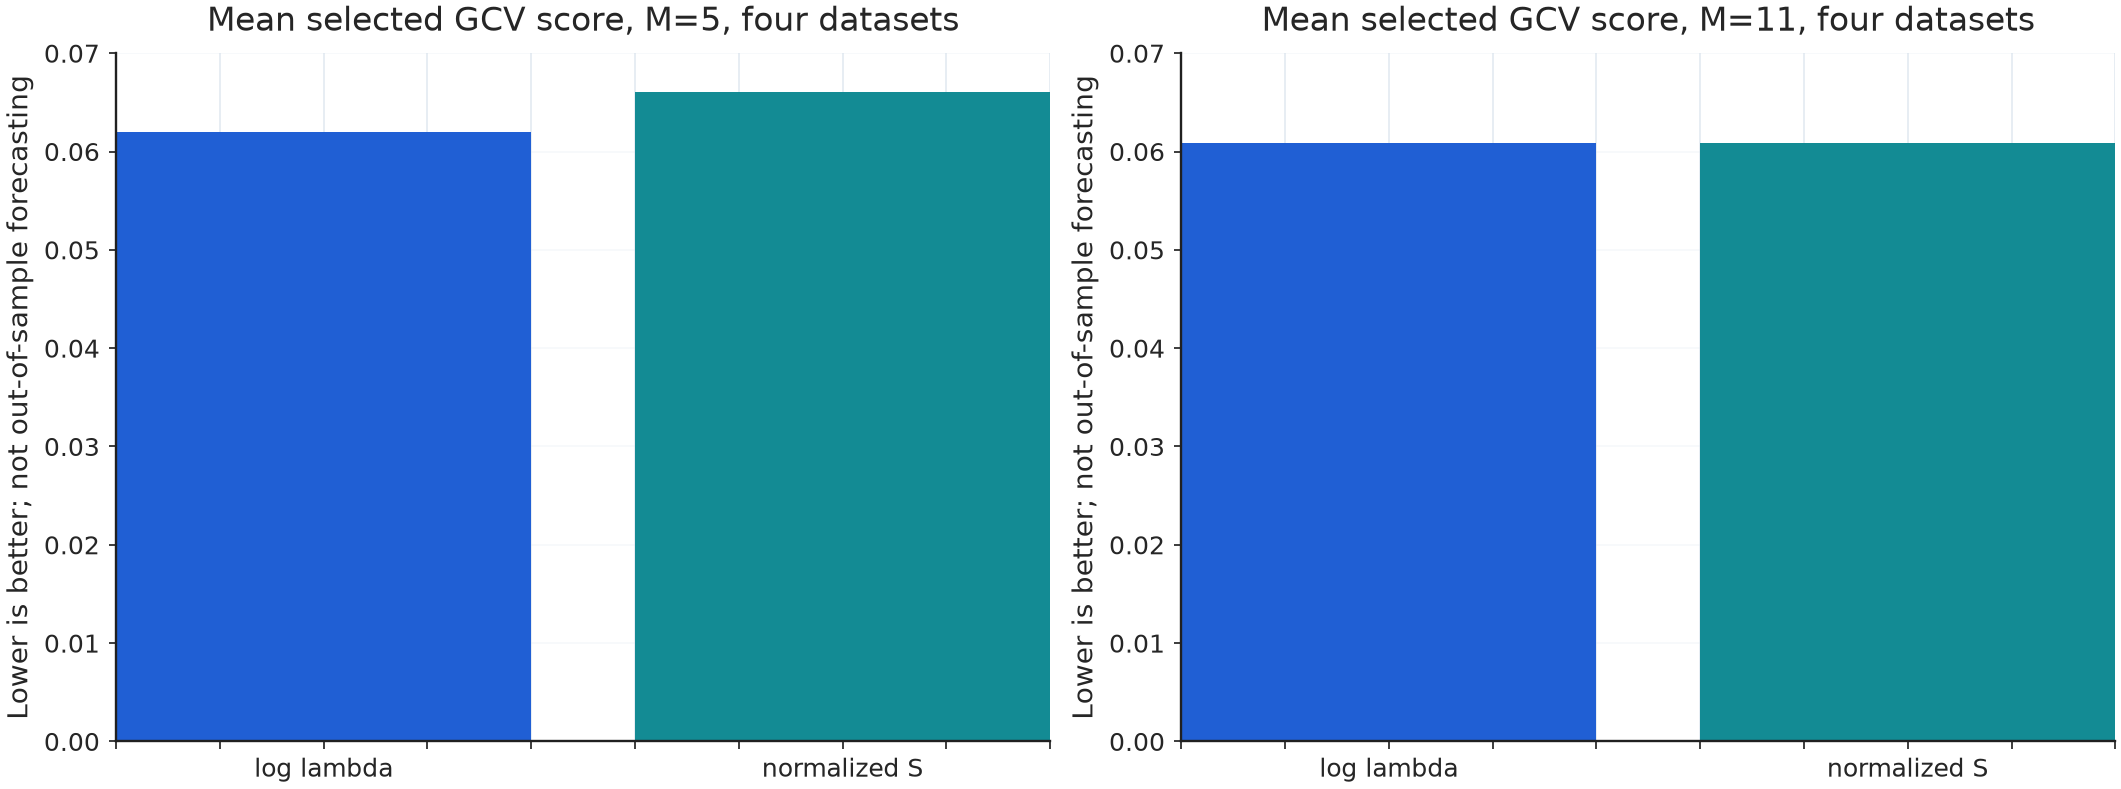

d=1: evaluated S range [0.0010, 0.9872]; S->lambda map time=1.870 ms
d=2: evaluated S range [0.0015, 0.9279]; S->lambda map time=1.831 ms
d=3: evaluated S range [0.0023, 0.8712]; S->lambda map time=1.811 ms
d=4: evaluated S range [0.0038, 0.8269]; S->lambda map time=1.858 ms


In [6]:
fig,axes=plt.subplots(1,2,figsize=(11.8,4.4),layout="constrained")
for ax,M in zip(axes,(5,11)):
    vals={}
    for policy in ("log_lambda","uniform_s"):
        rs=subset(n=48,d=2,M=M,R=4,mu=0.0,
                  reuse="warm",grid_policy=policy,method="spectral")
        assert len(rs)==1
        vals[policy]=rs[0]
    for i,policy in enumerate(("log_lambda","uniform_s")):
        ax.bar(i,float(vals[policy]["selected_score_mean"]),
               color=("#205fd4","#138b94")[i])
    ax.set_xticks((0,1),("log lambda","normalized S"))
    ax.set(title=f"Mean selected GCV score, M={M}, four datasets",
           ylabel="Lower is better; not out-of-sample forecasting")
    ax.grid(axis="y",alpha=.2)
plt.show()
for d in sorted({int(r["d"]) for r in bounds}):
    hit=next(r for r in bounds if int(r["d"])==d
             and int(r["M"])==11 and r["grid_policy"]=="uniform_s")
    print(f"d={d}: evaluated S range [{float(hit['S_min']):.4f},"
          f" {float(hit['S_max']):.4f}]; "
          f"S->lambda map time={1000*float(hit['mapping_s']):.3f} ms")


## What can we conclude?

- **Repeated grid search on the same penalty candidates:** reusing Cholesky factors (and EDF) across *independent series* may considerably reduce runtime.
- **One new search over a different grid:** Cholesky must factor each *new* matrix $I+\lambda Q$. It does **not** reuse one Cholesky factor across different $\lambda$ values.
- **Large $d$:** a wider band increases banded arithmetic and can affect numerical conditioning; comparisons must keep $n,M,R,\mu$ fixed.
- **One-shot GCV:** spectral SVD may win because GCV requires EDF traces; full-fit-only banded Cholesky speedups cannot automatically be transferred to GCV.
- **Different $\mu$:** a fixed reference mean alters the right-hand sides and criterion values but not $Q$ or EDF. This is not the same as optimizing $\mu$ jointly with $\lambda$.
- **Different grid policies:** identical endpoints and budget do not guarantee identical optimum scores. The normalized-S mapping cost is a one-off common setup cost, reported separately.

This benchmark uses genuine **classical in-sample GCV**, not LOOCV, time-series CV, or rolling forecast validation. For independent repeated observations, datasets are seeded and reused across all backends and the two $\mu$ values. The reference runner uses one machine/session; there are no publication-grade multi-session confidence intervals yet.

### Windows 11 PowerShell (run on your own computer)

```powershell
git pull origin main
conda activate trendestimation
python -m pip install -e ".[dev,docs,plot]" threadpoolctl
python paper\benchmarks\grid_reuse_study.py --preset quick --repeats 3
python paper\benchmarks\grid_reuse_study.py --preset full --repeats 7
```

Local outputs are saved under `paper/benchmarks/results/grid_reuse/`; the committed notebook uses separately labeled measurements from GitHub's Linux runner. To rerender the notebook using your Windows results, use `--output-dir paper/benchmarks/grid_reuse_reference` explicitly, and retain machine provenance. No computed timing should be presented as universal.